In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import glob
from utils import paths
import os
import dask.dataframe as dd

In [ ]:
#make a dictionary with the dataframes of all the places
dfs = {}

#extremem event data
file = 'output_hhprocess/updated/allsites_training_dd_clipped.csv'
df = pd.read_csv(file)

for site, group_df in df.groupby('SITE_ID'):
    dfs[site] = group_df.reset_index(drop=True)

print(dfs['CN-Cha']['day'])

0      2003-04-24
1      2003-04-25
2      2003-04-26
3      2003-04-29
4      2003-04-30
          ...    
307    2005-10-06
308    2005-10-08
309    2005-10-09
310    2005-10-10
311    2005-10-11
Name: day, Length: 312, dtype: object


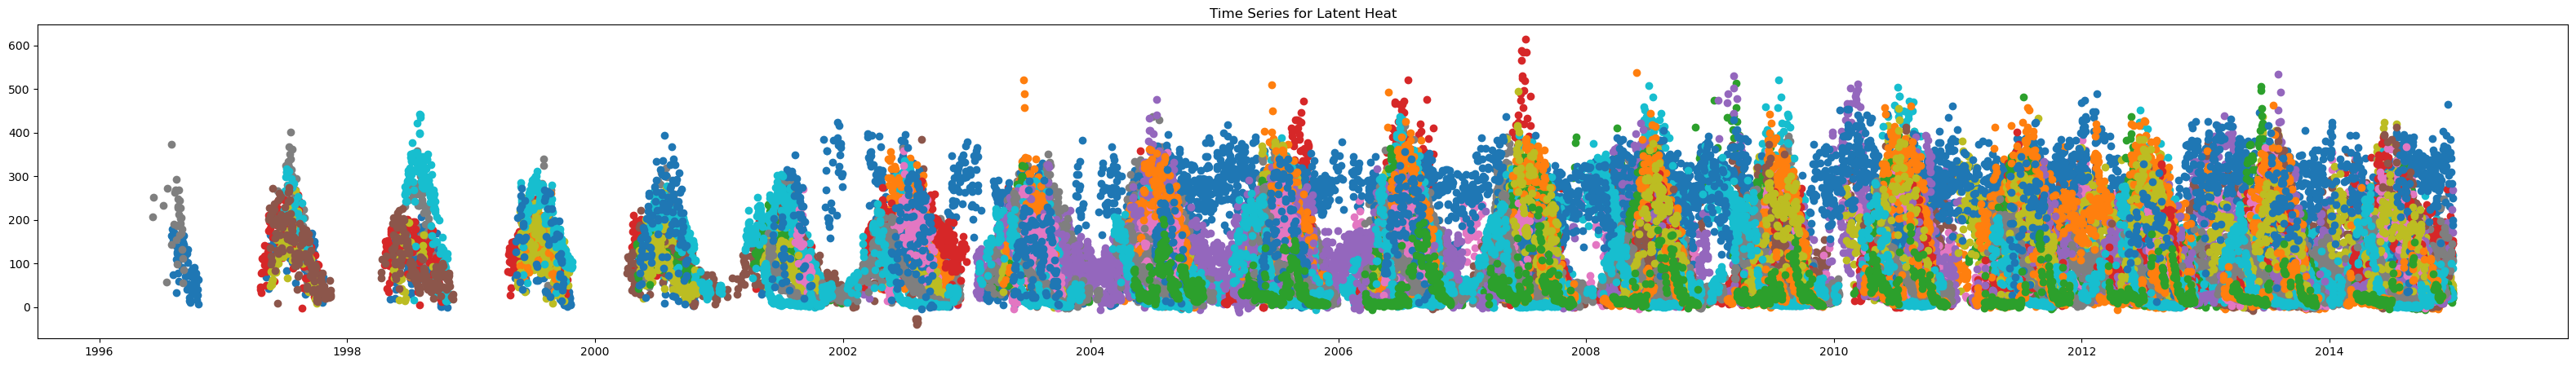

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(40,5))

for site in dfs:
    dfs[site]['day'] = pd.to_datetime(dfs[site]['day'])
    plt.scatter(dfs[site]["day"], dfs[site]["LE_F_MDS"])
    plt.title("Time Series for Latent Heat")


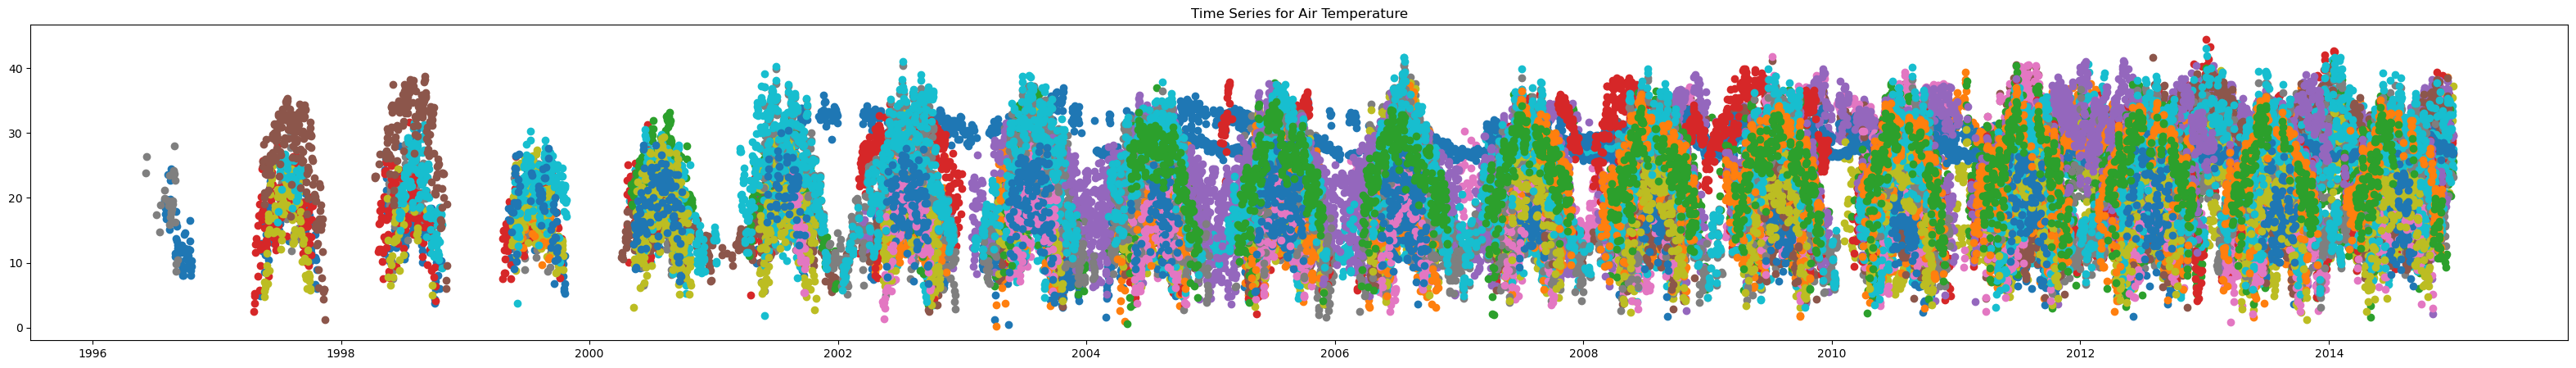

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(40,5))

for site in dfs:
    dfs[site]['day'] = pd.to_datetime(dfs[site]['day'])
    plt.scatter(dfs[site]["day"], dfs[site]["TA_F"])
    plt.title("Time Series for Air Temperature")


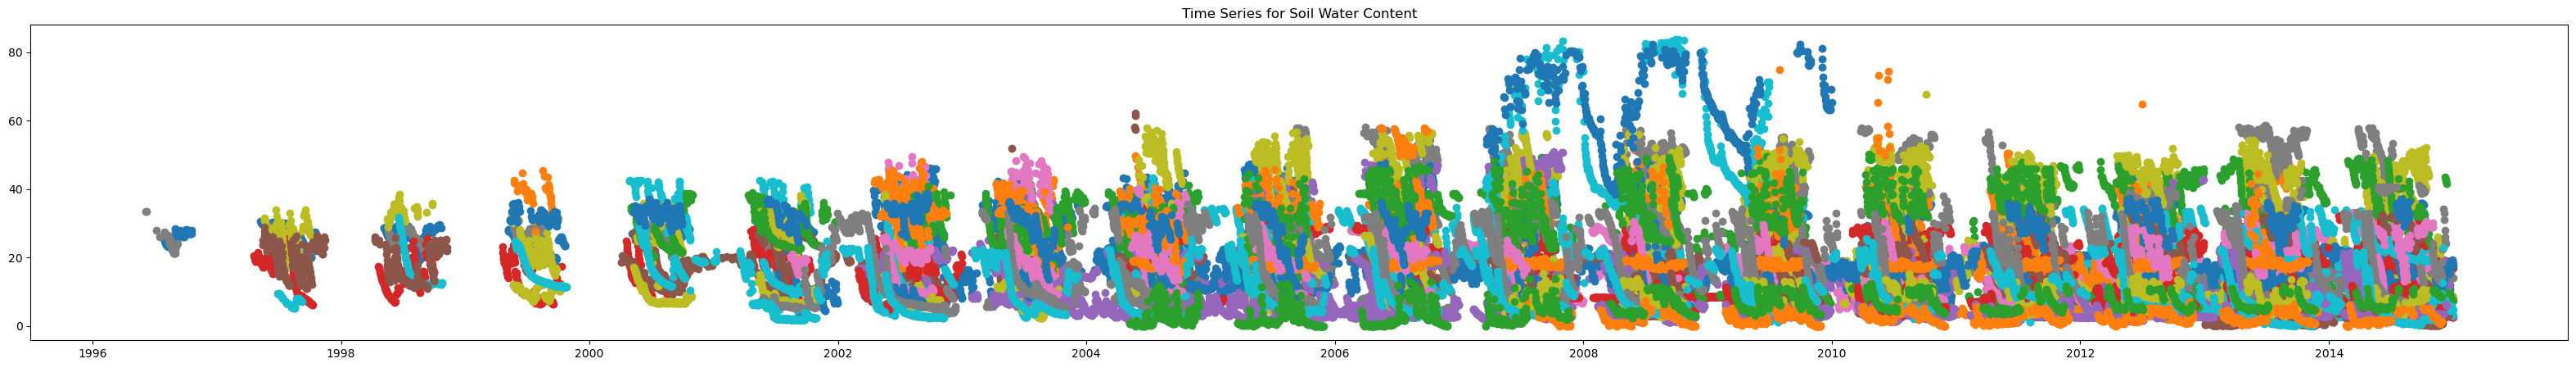

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(40,5))

for site in dfs:
    dfs[site]['day'] = pd.to_datetime(dfs[site]['day'])
    plt.scatter(dfs[site]["day"], dfs[site]["SWC_F_MDS_1"])
    plt.title("Time Series for Soil Water Content")


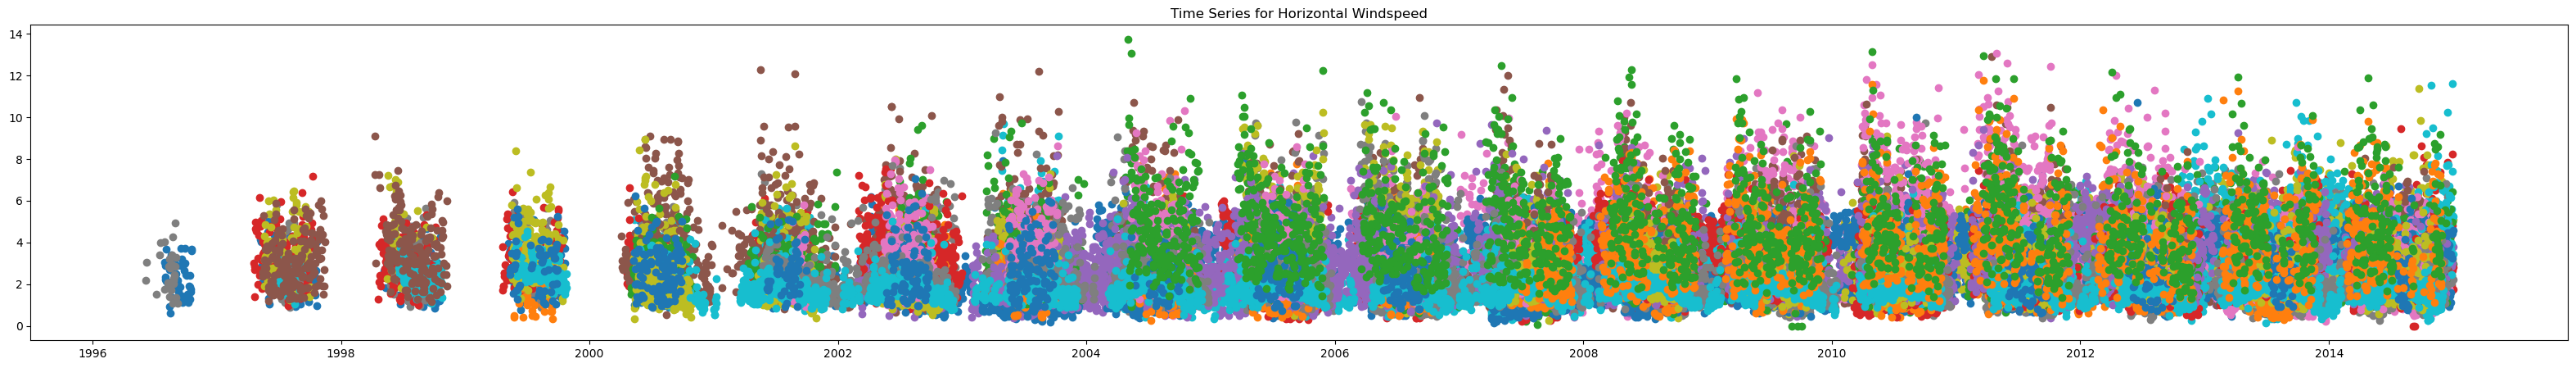

In [13]:
import matplotlib.pyplot as plt
plt.figure(figsize=(40,5))

for site in dfs:
    dfs[site]['day'] = pd.to_datetime(dfs[site]['day'])
    plt.scatter(dfs[site]["day"], dfs[site]["WS_F"])
    plt.title("Time Series for Horizontal Windspeed")


In [15]:
df3 = pd.read_csv('/Users/pavan/Documents/ERICA RESEARCH/testing/wet-extremes-photosynthesis-main/runs/RF/default_run_name/performance.csv')

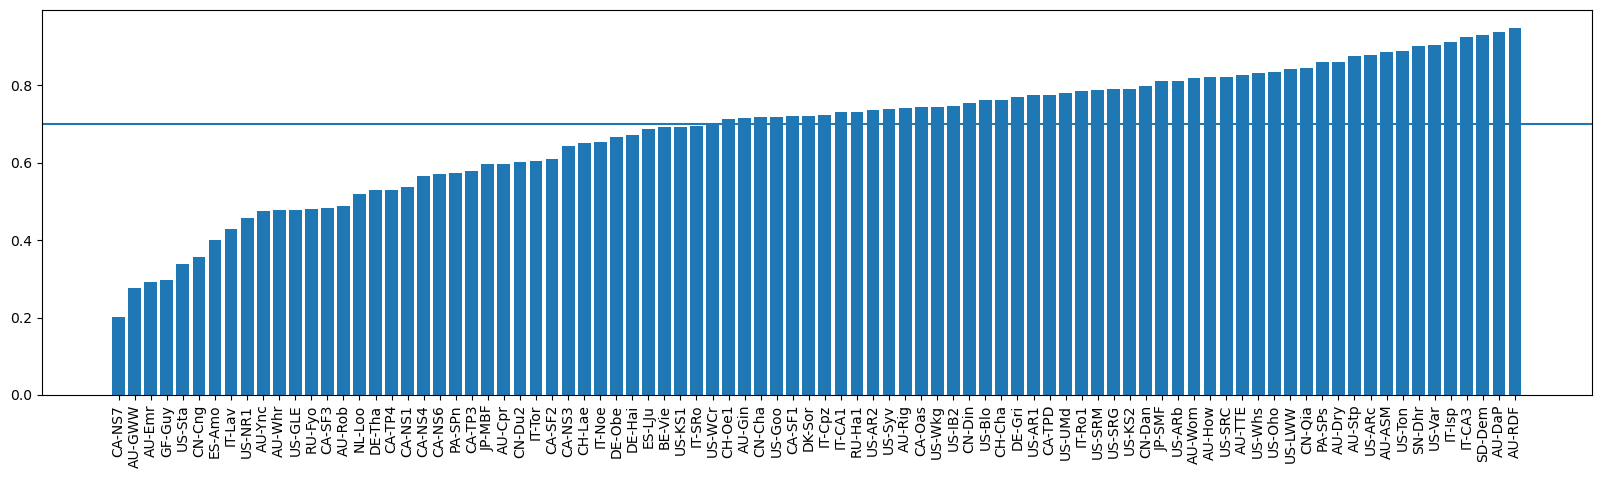

In [17]:
df3 = df3.sort_values('test_score')
plt.figure(figsize=(20,5))
plt.bar(df3["SITE_ID"], df3["test_score"])
plt.axhline(0.7)
plt.xticks(rotation=90);

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

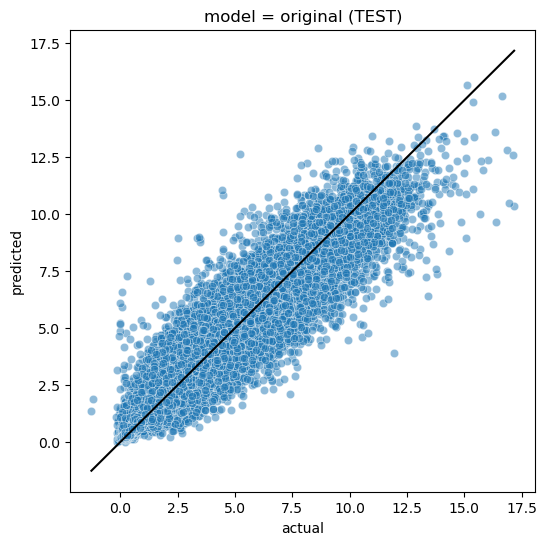

In [89]:
#using 'TA_F', 'RH', 'WS_F', 'P_F_lag_sum', 'GPP_lag_mean'

test_data = pd.read_csv("runs/RF/original_run/test.csv")

plt.figure(figsize=(6,6))
sns.scatterplot(x="actual", y="predicted", data=test, alpha=0.5)
plt.plot([test_data.actual.min(), test_data.actual.max()], [test_data.actual.min(), test_data.actual.max()], 'black')
plt.xlabel("actual")
plt.ylabel("predicted")
plt.title("model = original (TEST)")
plt.show()

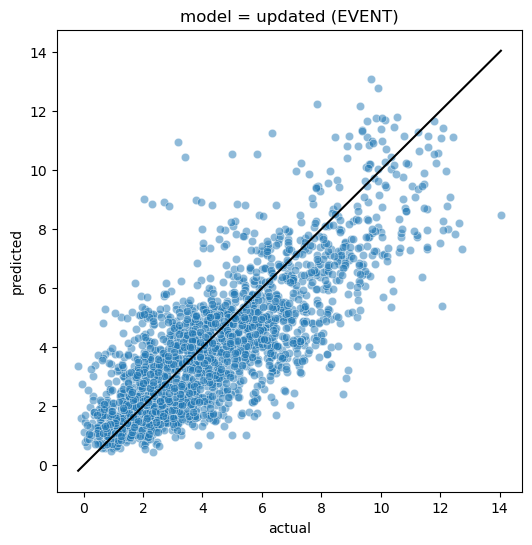

In [91]:
#EVENT
event_data = pd.read_csv("runs/RF/original_run/event.csv")
plt.figure(figsize=(6,6))
sns.scatterplot(x="actual", y="predicted", data=event_data, alpha=0.5)
plt.plot([event_data.actual.min(), event_data.actual.max()], [event_data.actual.min(), event_data.actual.max()], 'black')
plt.xlabel("actual")
plt.ylabel("predicted")
plt.title("model = updated (EVENT)")
plt.show()

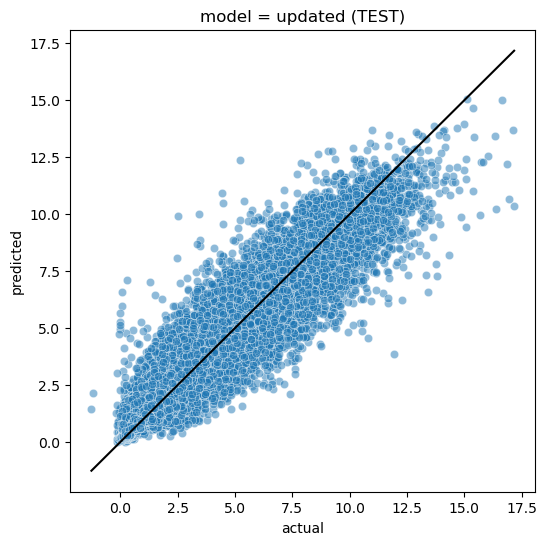

In [85]:
#using 'SWC_F_MDS_1','WS_F','TA_F','RH','VPD_F','SW_IN_F','P_F','GPP_DT_VUT_REF','GPP_NT_VUT_REF'
test_data = pd.read_csv("runs/RF/updated_run/test.csv")

plt.figure(figsize=(6,6))
sns.scatterplot(x="actual", y="predicted", data=test_data, alpha=0.5)
plt.plot([test_data.actual.min(), test_data.actual.max()], [test_data.actual.min(), test_data.actual.max()], 'black')
plt.xlabel("actual")
plt.ylabel("predicted")
plt.title("model = updated (TEST)")
plt.show()

In [ ]:
#using 'SWC_F_MDS_1','WS_F','TA_F','RH','VPD_F','SW_IN_F','P_F','GPP_DT_VUT_REF','GPP_NT_VUT_REF'

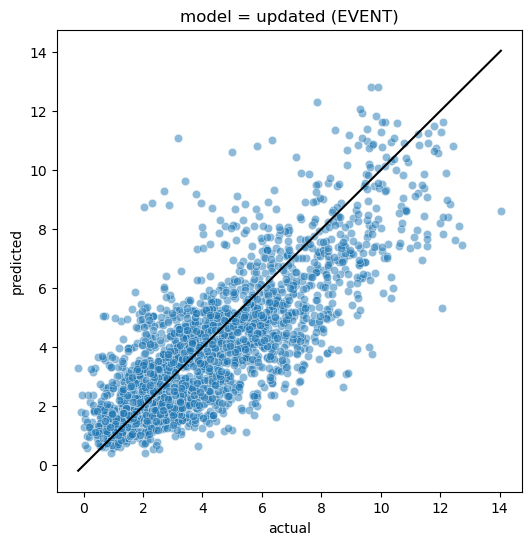

In [107]:
#EVENT
event_data = pd.read_csv("runs/RF/updated_run/event.csv")
plt.figure(figsize=(6,6))
sns.scatterplot(x="actual", y="predicted", data=event_data, alpha=0.5)
plt.plot([event_data.actual.min(), event_data.actual.max()], [event_data.actual.min(), event_data.actual.max()], 'black')
plt.xlabel("actual")
plt.ylabel("predicted")
plt.title("model = updated (EVENT)")
plt.show()

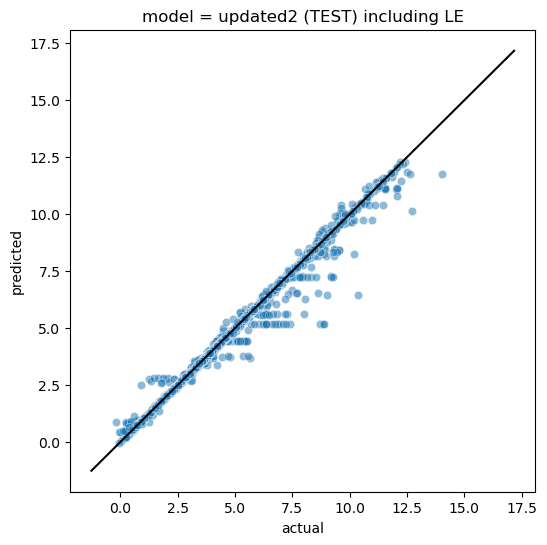

In [147]:
#(WITH LE)

#using 'SWC_F_MDS_1','WS_F','TA_F','RH','VPD_F','SW_IN_F','P_F','GPP_DT_VUT_REF','GPP_NT_VUT_REF','LE_F_MDS'

#TEST
test_data = pd.read_csv("runs/RF/updated_run2/test.csv")
plt.figure(figsize=(6,6))
sns.scatterplot(x="actual", y="predicted", data=event_data, alpha=0.5)
plt.plot([test_data.actual.min(), test_data.actual.max()], [test_data.actual.min(), test_data.actual.max()], 'black')
plt.xlabel("actual")
plt.ylabel("predicted")
plt.title("model = updated2 (TEST) including LE")
plt.show()

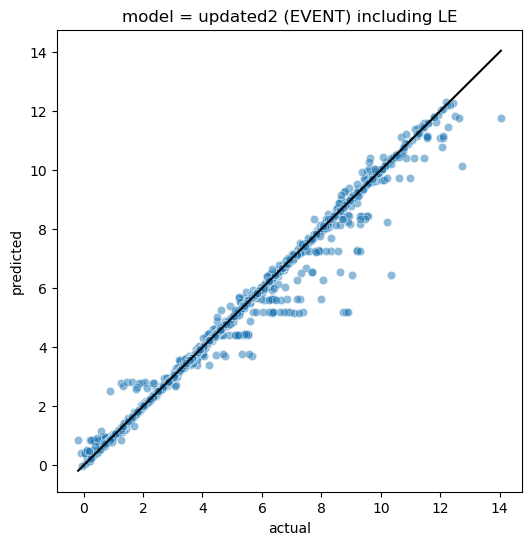

In [149]:
#(WITH LE)

#using 'SWC_F_MDS_1','WS_F','TA_F','RH','VPD_F','SW_IN_F','P_F','GPP_DT_VUT_REF','GPP_NT_VUT_REF','LE_F_MDS'

#EVENT
event_data = pd.read_csv("runs/RF/updated_run2/event.csv")
plt.figure(figsize=(6,6))
sns.scatterplot(x="actual", y="predicted", data=event_data, alpha=0.5)
plt.plot([event_data.actual.min(), event_data.actual.max()], [event_data.actual.min(), event_data.actual.max()], 'black')
plt.xlabel("actual")
plt.ylabel("predicted")
plt.title("model = updated2 (EVENT) including LE")
plt.show()

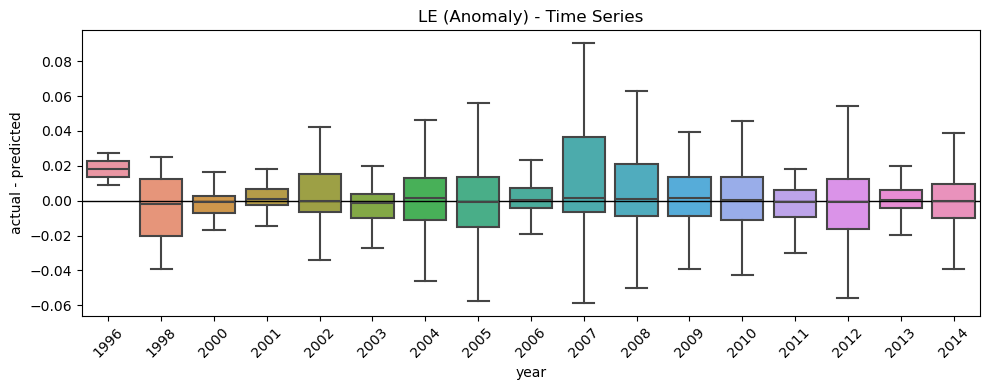

In [153]:
df = pd.read_csv("/Users/pavan/Documents/ERICA RESEARCH/testing/wet-extremes-photosynthesis-main/runs/RF/updated_run2/event.csv")
df['day'] = pd.to_datetime(df['day'])
df['year'] = df['day'].dt.year

plt.figure(figsize=(10,4))
sns.boxplot(x='year', y='actual - predicted', data=df, showfliers=False)
plt.axhline(0, color='black', linewidth=1)
plt.title("LE (Anomaly) - Time Series")
plt.ylabel("actual - predicted")
plt.xlabel("year")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()